# SAR Speckle Denoising & Water Segmentation (Sen1Floods11, 100 patches)
Compares **Median / Lee / Frost** filters with a **compact self-supervised (Noise2Void-style) conv autoencoder** on Sentinel-1 VV patches, then segments water with the `VV < -17 dB` threshold (reused from the Tirupati project).
Metrics: **ENL** (real data, homogeneous GT-water blocks), **PSNR** (simulated speckle on a GT-derived two-class phantom, since real data has no clean reference), **IoU / F1** vs. hand labels.

In [1]:
!pip -q install rasterio

In [2]:
import os, csv, urllib.request
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, rasterio
import scipy.ndimage as ndi
import matplotlib.pyplot as plt
import torch, torch.nn as nn

# ---------------- configuration ----------------
SEED = 0
USE_DRIVE = False                          # True: mount Drive and read patches from DATA_DIR on Drive
DATA_DIR = "/content/sen1floods11_100"     # must contain S1Hand/ and LabelHand/ (Drive example: /content/drive/MyDrive/sen1floods11_100)
N_PATCHES = 100
GCS = "https://storage.googleapis.com/sen1floods11/v1.1"
SPLIT_CSV = GCS + "/splits/flood_handlabeled/flood_train_data.csv"
S1_URL, LBL_URL = GCS + "/data/flood_events/HandLabeled/S1Hand", GCS + "/data/flood_events/HandLabeled/LabelHand"

WATER_DB = -17.0          # reused: water = VV_dB < -17
ENL_LOOKS = 4.4           # assumed nominal ENL of S1 GRD IW (Lee noise variation coefficient, speckle simulation)
WIN = 5                   # window for Median / Lee / Frost
FROST_DAMP = 2.0
ENL_BLOCK = 16            # homogeneous-block size (px) for real-data ENL
SPLIT = (0.6, 0.2, 0.2)   # train / val / test (by patch)
# self-supervised autoencoder (reused architecture/hyper-params, Noise2Void masking added)
PATCH, EMB, EPOCHS, BATCH, LR = 64, 32, 20, 32, 1e-3
N_CROPS, MASK_FRAC = 3000, 0.02

if USE_DRIVE:
    from google.colab import drive; drive.mount("/content/drive")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
print("device:", DEVICE)

device: cpu


## Data: download (or reuse) the 100 hand-labeled patches, validate

In [4]:
def fetch(url, dest):
    if os.path.exists(dest) and os.path.getsize(dest) > 0: return
    os.makedirs(os.path.dirname(dest), exist_ok=True)
    urllib.request.urlretrieve(url, dest)

s1_dir, lbl_dir = f"{DATA_DIR}/S1Hand", f"{DATA_DIR}/LabelHand"
if os.path.isdir(s1_dir) and len(os.listdir(s1_dir)) > 0:
    names = sorted(os.listdir(s1_dir))[:N_PATCHES]                # local / Drive copy
else:
    os.makedirs(DATA_DIR, exist_ok=True); fetch(SPLIT_CSV, f"{DATA_DIR}/split.csv")
    with open(f"{DATA_DIR}/split.csv") as f:
        names = [r[0] for r in csv.reader(f) if r][:N_PATCHES]
names = sorted(names)                                           # same order/split on every run
assert all("S1Hand" in n for n in names), "unexpected file names"
lbl_names = [n.replace("S1Hand", "LabelHand") for n in names]
with ThreadPoolExecutor(8) as ex:
    list(ex.map(lambda a: fetch(*a), [(f"{S1_URL}/{n}", f"{s1_dir}/{n}") for n in names]
                                   + [(f"{LBL_URL}/{n}", f"{lbl_dir}/{n}") for n in lbl_names]))

VV, LAB = [], []
for n, ln in zip(names, lbl_names):
    with rasterio.open(f"{s1_dir}/{n}") as s:
        vv = s.read(1).astype("float64")                           # band 0 = VV (dB); band 1 = VH (unused)
        if s.nodata is not None: vv[vv == s.nodata] = np.nan
    with rasterio.open(f"{lbl_dir}/{ln}") as s: lab = s.read(1).astype("int16")   # 1 water, 0 land, -1 nodata
    vv[~np.isfinite(vv)] = np.nan
    assert vv.shape == lab.shape, f"{n}: image/label shape mismatch"

    # Filter out patches that are mostly nodata
    if np.isfinite(vv).mean() > 0.5:
        VV.append(vv)
        LAB.append(lab)
    else:
        print(f"Skipping mostly-nodata patch: {n}")

# validation
allv = np.concatenate([v[np.isfinite(v)] for v in VV])
assert set(np.unique(np.concatenate([l.ravel() for l in LAB]))) <= {-1, 0, 1}, "unexpected label values"
assert np.median(allv) < 0, "VV median >= 0: data looks linear, not dB"
assert all(np.isfinite(v).mean() > 0.5 for v in VV), "a patch is mostly nodata"
water_frac = np.mean([(l == 1).sum() / max((l >= 0).sum(), 1) for l in LAB])
print(f"{len(VV)} patches, shapes {sorted({v.shape for v in VV})}, VV dB median {np.median(allv):.1f}, mean GT water fraction {water_frac:.2%}")

# patch-level train/val/test split (no labels used for training the AE; val tunes thresholds; test reports)
perm = rng.permutation(len(VV)); a, b = int(SPLIT[0]*len(VV)), int((SPLIT[0]+SPLIT[1])*len(VV))
idx_tr, idx_va, idx_te = perm[:a], perm[a:b], perm[b:]
print("train/val/test:", len(idx_tr), len(idx_va), len(idx_te))

Skipping mostly-nodata patch: Ghana_134751_S1Hand.tif
Skipping mostly-nodata patch: Ghana_135389_S1Hand.tif
Skipping mostly-nodata patch: India_979278_S1Hand.tif
97 patches, shapes [(512, 512)], VV dB median -9.1, mean GT water fraction 12.42%
train/val/test: 58 19 20


## Speckle filters (applied in the linear-intensity domain) and helpers

In [5]:
db2lin = lambda d: np.power(10.0, d / 10.0)
lin2db = lambda x: 10.0 * np.log10(np.maximum(x, 1e-10))
def fill(db): return np.where(np.isfinite(db), db, np.nanmedian(db))     # nodata -> image median (for filtering only)

def _loc_stats(x, win):
    m = ndi.uniform_filter(x, win, mode="reflect"); m2 = ndi.uniform_filter(x * x, win, mode="reflect")
    v = np.maximum(m2 - m * m, 0.0)
    return m, v / np.maximum(m * m, 1e-12)                                # local mean, squared coeff. of variation

def lee(x, win=WIN, cu2=1.0 / ENL_LOOKS):
    m, ci2 = _loc_stats(x, win)
    w = np.clip(1.0 - cu2 / np.maximum(ci2, 1e-12), 0.0, 1.0)
    return m + w * (x - m)

def frost(x, win=WIN, damp=FROST_DAMP):
    r = win // 2; H, W = x.shape
    _, ci2 = _loc_stats(x, win); a = damp * ci2
    xp = np.pad(x, r, mode="reflect"); num = np.zeros_like(x); den = np.zeros_like(x)
    for dy in range(-r, r + 1):
        for dx in range(-r, r + 1):
            w = np.exp(-a * np.hypot(dy, dx))
            num += w * xp[r + dy:r + dy + H, r + dx:r + dx + W]; den += w
    return num / den

def median(x, win=WIN): return ndi.median_filter(x, size=win, mode="reflect")

def classical(fn):
    """dB image (NaN=nodata) -> filtered dB image, filter run on linear intensity."""
    def run(db):
        out = lin2db(fn(db2lin(fill(db))))
        return np.where(np.isfinite(db), out, np.nan)
    return run

## Compact self-supervised autoencoder (reused `ConvAE`, trained Noise2Void-style)
A plain reconstruction AE would learn the identity and keep speckle. Here random pixels are replaced by a neighbour and the loss is computed **only at those pixels**, so the net must predict a pixel from its context (speckle is ~uncorrelated, signal is not). No clean images or labels are used; training uses train-split images only.

In [6]:
def norm_db(db):                         # dB -> [0,1]; NaN -> image median (reference used the -30 dB floor)
    x = np.clip(fill(db), -30.0, 0.0); return ((x + 30.0) / 30.0).astype("float32"), np.isfinite(db)

class ConvAE(nn.Module):                 # architecture reused from analyze_water.py
    def __init__(self, emb=EMB):
        super().__init__()
        self.encoder = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(True), nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(True),
                                     nn.Conv2d(32, emb, 3, padding=1), nn.ReLU(True))
        self.decoder = nn.Sequential(nn.Conv2d(emb, 32, 3, padding=1), nn.ReLU(True), nn.Conv2d(32, 16, 3, padding=1), nn.ReLU(True),
                                     nn.Conv2d(16, 1, 3, padding=1))
    def forward(self, x): return self.decoder(self.encoder(x))

NORM = {}
def sample_crops(idx, n):
    out, tries = [], 0
    while len(out) < n:
        tries += 1
        if tries > 50 * n: raise RuntimeError("cannot find enough valid training crops")
        k_ = rng.choice(idx); db = VV[int(k_)]; H, W = db.shape
        if H < PATCH or W < PATCH: continue
        i, j = int(rng.integers(0, H - PATCH + 1)), int(rng.integers(0, W - PATCH + 1))
        if np.isfinite(db[i:i+PATCH, j:j+PATCH]).mean() < 0.5: continue   # skip mostly-nodata crops
        k = int(k_); NORM.setdefault(k, norm_db(VV[k])[0]); out.append(NORM[k][i:i+PATCH, j:j+PATCH])
    return torch.from_numpy(np.stack(out))[:, None]

def n2v_mask(b):
    B, _, P, _ = b.shape
    mask = torch.rand(B, 1, P, P, device=b.device) < MASK_FRAC
    dy = torch.randint(-2, 3, (B, 1, P, P), device=b.device); dx = torch.randint(-2, 3, (B, 1, P, P), device=b.device)
    dx = torch.where((dy == 0) & (dx == 0), torch.ones_like(dx), dx)      # never copy the pixel itself
    ar = torch.arange(P, device=b.device)
    iy = (ar[None, None, :, None] + dy).clamp(0, P - 1); ix = (ar[None, None, None, :] + dx).clamp(0, P - 1)
    nb = b.reshape(B, 1, -1).gather(2, (iy * P + ix).reshape(B, 1, -1)).reshape(B, 1, P, P)
    return torch.where(mask, nb, b), mask

def n2v_loss(model, b):
    inp, mask = n2v_mask(b)
    return ((model(inp) - b) ** 2)[mask].mean()

Xtr, Xva = sample_crops(idx_tr, N_CROPS).to(DEVICE), sample_crops(idx_va, 500).to(DEVICE)
model = ConvAE().to(DEVICE); opt = torch.optim.Adam(model.parameters(), lr=LR)
print(f"[ae] training on {len(Xtr)} crops ({PATCH}x{PATCH}), {EPOCHS} epochs")
for ep in range(EPOCHS):
    model.train(); p = torch.randperm(len(Xtr), device=DEVICE); tot = 0.0
    for k in range(0, len(Xtr), BATCH):
        b = Xtr[p[k:k+BATCH]]; opt.zero_grad(); loss = n2v_loss(model, b); loss.backward(); opt.step(); tot += loss.item() * len(b)
    if ep % 5 == 0 or ep == EPOCHS - 1:
        model.eval()
        with torch.no_grad(): vl = n2v_loss(model, Xva).item()
        print(f"  epoch {ep:2d}  train N2V-MSE {tot/len(Xtr):.5f}  val N2V-MSE {vl:.5f}")
model.eval()

def ae_denoise(db):
    x, valid = norm_db(db)
    with torch.no_grad(): y = model(torch.from_numpy(x)[None, None].to(DEVICE))[0, 0].cpu().numpy()
    return np.where(valid, np.clip(y, 0, 1) * 30.0 - 30.0, np.nan)

METHODS = {"raw": lambda d: d, "median": classical(median), "lee": classical(lee), "frost": classical(frost), "autoencoder": ae_denoise}

[ae] training on 3000 crops (64x64), 20 epochs
  epoch  0  train N2V-MSE 0.03887  val N2V-MSE 0.00615
  epoch  5  train N2V-MSE 0.00094  val N2V-MSE 0.00090
  epoch 10  train N2V-MSE 0.00066  val N2V-MSE 0.00072
  epoch 15  train N2V-MSE 0.00057  val N2V-MSE 0.00056
  epoch 19  train N2V-MSE 0.00052  val N2V-MSE 0.00051


## Metrics: ENL, PSNR, IoU/F1

In [7]:
def enl_of(lin_blocks):
    return float(np.median([b.mean() ** 2 / max(b.var(), 1e-20) for b in lin_blocks]))

def homogeneous_blocks(lab, valid, B=ENL_BLOCK):
    H, W = lab.shape
    return [(i, j) for i in range(0, H - B + 1, B) for j in range(0, W - B + 1, B)
            if (lab[i:i+B, j:j+B] == 1).all() and valid[i:i+B, j:j+B].all()]

def seg_counts(db, lab, thr):
    ve = np.isfinite(db) & (lab >= 0); pred = (db < thr) & ve; gt = (lab == 1) & ve
    return np.array([(pred & gt).sum(), (pred & ~gt).sum(), (~pred & gt & ve).sum()], dtype="float64")   # tp, fp, fn

def iou_f1(c):
    tp, fp, fn = c
    return tp / max(tp + fp + fn, 1), 2 * tp / max(2 * tp + fp + fn, 1)

def psnr(ref_db, est_db, valid):
    r, e = (np.clip(ref_db, -30, 0) + 30) / 30, (np.clip(est_db, -30, 0) + 30) / 30     # peak = 1 in normalised dB
    mse = ((r - e)[valid] ** 2).mean(); return 10 * np.log10(1.0 / max(mse, 1e-12))

# ---- sanity checks on synthetic data (filters actually remove multiplicative speckle; constants preserved) ----
_c = np.full((128, 128), 0.05); _s = _c * rng.gamma(ENL_LOOKS, 1 / ENL_LOOKS, _c.shape)
_enl = lambda z: z.mean() ** 2 / z.var()
for nm, fn in [("median", median), ("lee", lee), ("frost", frost)]:
    assert np.allclose(fn(_c), _c, atol=1e-9), nm + " alters a constant image"
    assert _enl(fn(_s)) > 1.5 * _enl(_s), nm + " does not increase ENL on synthetic speckle"
assert abs(_enl(_s) - ENL_LOOKS) < 1.0, "speckle simulator ENL off"
print("sanity checks passed")

sanity checks passed


## Run: denoise val/test patches, evaluate

In [8]:
eval_idx = list(idx_va) + list(idx_te)
den = {m: {i: fn(VV[i]).astype("float32") for i in eval_idx} for m, fn in METHODS.items()}   # val+test only (memory)

# ENL on GT-water 16x16 blocks (real data, val+test; labels not used for any training)
enl = {}
for m in METHODS:
    blocks = [den[m][i][r:r+ENL_BLOCK, c:c+ENL_BLOCK] for i in eval_idx
              for r, c in homogeneous_blocks(LAB[i], np.isfinite(VV[i]))]
    enl[m] = enl_of([db2lin(b.astype("float64")) for b in blocks]) if blocks else np.nan
    n_blocks = len(blocks)
print(f"ENL blocks: {n_blocks} (of {ENL_BLOCK}x{ENL_BLOCK}, fully GT-water)"); assert n_blocks > 0, "no homogeneous water blocks found; lower ENL_BLOCK"

# segmentation: fixed -17 dB, and threshold tuned on VAL (max pooled F1) per method, reported on TEST
grid = np.arange(-26, -7.9, 0.5); seg = {}
for m in METHODS:
    f1_val = [iou_f1(sum(seg_counts(den[m][i], LAB[i], t) for i in idx_va))[1] for t in grid]
    t_best = float(grid[int(np.argmax(f1_val))])
    fx = iou_f1(sum(seg_counts(den[m][i], LAB[i], WATER_DB) for i in idx_te))
    tn = iou_f1(sum(seg_counts(den[m][i], LAB[i], t_best) for i in idx_te))
    seg[m] = dict(IoU_fixed=fx[0], F1_fixed=fx[1], thr_tuned=t_best, IoU_tuned=tn[0], F1_tuned=tn[1])

# PSNR: simulated speckle on a two-class phantom built from GT (test patches); real data has no clean reference
ps = {m: [] for m in METHODS}; ps["noisy input"] = []
for i in idx_te:
    db, lab = VV[i], LAB[i]; ve = np.isfinite(db) & (lab >= 0); lin = db2lin(db)
    wat, lnd = ve & (lab == 1), ve & (lab == 0)
    mw = lin[wat].mean() if wat.any() else 0.0; ml = lin[lnd].mean() if lnd.any() else lin[ve].mean()
    clean = np.where(lab == 1, mw, ml); noisy_db = lin2db(clean * rng.gamma(ENL_LOOKS, 1 / ENL_LOOKS, clean.shape))
    ps["noisy input"].append(psnr(lin2db(clean), noisy_db, ve))
    for m, fn in METHODS.items(): ps[m].append(psnr(lin2db(clean), fn(noisy_db), ve))

table = pd.DataFrame(seg).T.reindex(["noisy input"] + list(METHODS))
table.insert(0, "PSNR_dB(sim)", pd.Series({m: np.mean(v) for m, v in ps.items()}))
table.insert(0, "ENL(real)", pd.Series(enl))
print(f"test patches: {len(idx_te)}, val patches (threshold tuning): {len(idx_va)}")
display(table.round(3))

ENL blocks: 1585 (of 16x16, fully GT-water)
test patches: 20, val patches (threshold tuning): 19


,ENL(real),PSNR_dB(sim),IoU_fixed,F1_fixed,thr_tuned,IoU_tuned,F1_tuned
noisy input,NaN,22.491,NaN,NaN,NaN,NaN,NaN
raw,2.833,22.491,0.506,0.672,-14.0,0.523,0.687
median,8.956,31.877,0.515,0.680,-13.0,0.571,0.727
lee,7.184,33.596,0.501,0.668,-12.5,0.565,0.722
frost,7.429,34.325,0.499,0.666,-12.5,0.564,0.721
autoencoder,3.080,23.006,0.510,0.676,-14.0,0.538,0.700


## Visual check (test patch with most GT water)

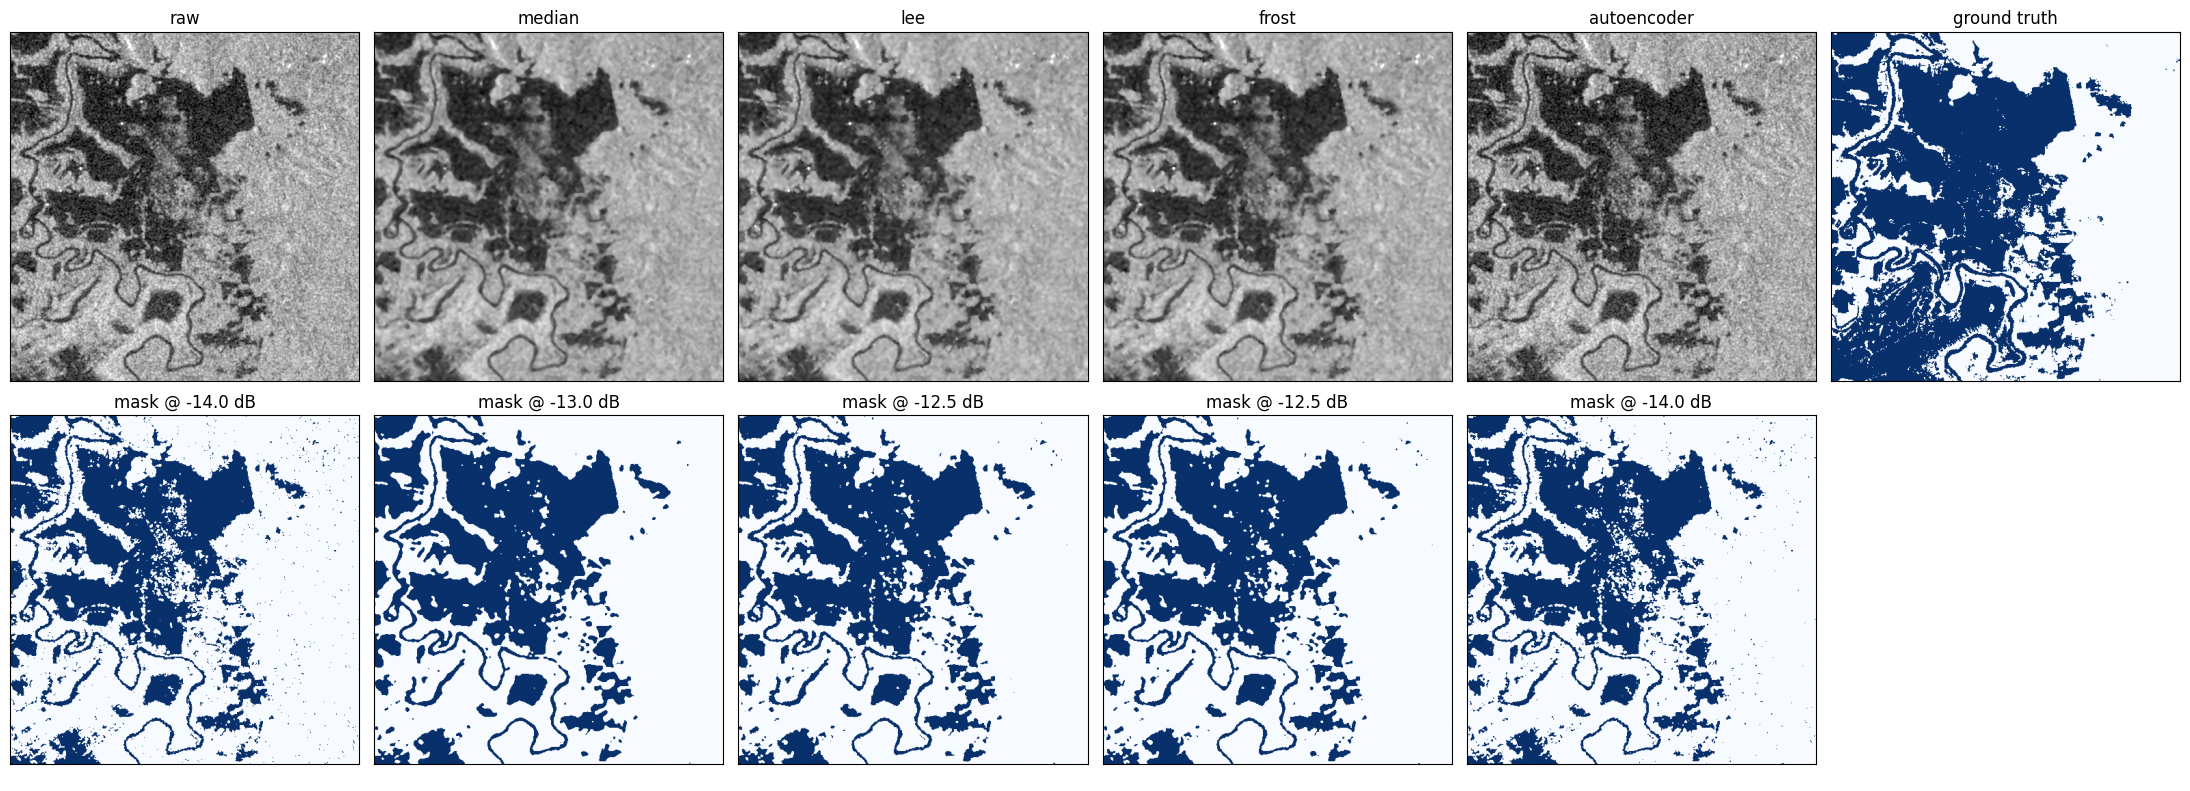

In [9]:
i = max(idx_te, key=lambda k: (LAB[k] == 1).sum()); names_m = list(METHODS)
fig, ax = plt.subplots(2, 6, figsize=(22, 8))
for k, m in enumerate(names_m):
    ax[0, k].imshow(den[m][i], cmap="gray", vmin=-25, vmax=0); ax[0, k].set_title(m)
    ax[1, k].imshow(den[m][i] < seg[m]["thr_tuned"], cmap="Blues"); ax[1, k].set_title(f"mask @ {seg[m]['thr_tuned']:.1f} dB")
ax[0, 5].imshow(np.ma.masked_where(LAB[i] < 0, LAB[i]), cmap="Blues"); ax[0, 5].set_title("ground truth")
ax[1, 5].axis("off")
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Notes
* ENL is measured on fully GT-water blocks of val+test patches; higher ENL means more smoothing, so read it together with IoU/F1.
* PSNR uses simulated Gamma speckle (L = `ENL_LOOKS`) on a two-class phantom (water/land mean intensities from each test patch); it measures noise suppression on idealised data, not fidelity on real texture.
* `*_tuned` thresholds are chosen on the validation patches and reported on test; `*_fixed` uses the reference `-17 dB`.
* Patches are split at patch level; spatially adjacent chips from the same flood event may be correlated.